# Klasifikasi Kesegaran Buah

**Anggota kelompok**
- Carlos Leonardo J. Dongoran
- Joni Fernando
- Matthew Rivandi
- Percaya Mendrova
- Yohanes Cornelius Willfredi Simanjuntak

Rincian pembagian kerja ada di `docs/pembagian_tugas.md`.

## Pembagian tugas

| Anggota | Tugas sementara |
|---|---|
| Carlos Leonardo J. Dongoran | Sementara mengerjakan persiapan dan eksplorasi awal notebook (bagian 1–5). |
| Joni Fernando | Belum ditentukan; pembagian tugas menyusul. |
| Matthew Rivandi | Belum ditentukan; pembagian tugas menyusul. |
| Percaya Mendrova | Belum ditentukan; pembagian tugas menyusul. |
| Yohanes Cornelius Willfredi Simanjuntak | Belum ditentukan; pembagian tugas menyusul. |

Pembagian tugas anggota lainnya akan ditetapkan kemudian. Rincian status sementara ada di `docs/pembagian_tugas.md`.

## 1. Import library, seed, versi TensorFlow, GPU, dan konfigurasi

Seed digunakan agar pemilihan contoh gambar dan eksperimen lebih mudah diulang. Sel setup menampilkan versi TensorFlow dan GPU yang tersedia; TensorFlow bersifat opsional untuk tahap eksplorasi dataset. Ubah konfigurasi sesuai kebutuhan.

In [7]:
from pathlib import Path
import math
import random
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError

try:
    import tensorflow as tf
except ModuleNotFoundError as error:
    if error.name != "tensorflow":
        raise
    tf = None

BENIH_ACAK = 42
UKURAN_GAMBAR = (224, 224)
UKURAN_BATCH = 32
JUMLAH_EPOCH = 20
LAJU_BELAJAR = 1e-4
CONTOH_PER_KELAS = 1

random.seed(BENIH_ACAK)
np.random.seed(BENIH_ACAK)
if tf is not None:
    tf.random.set_seed(BENIH_ACAK)

FOLDER_PROYEK = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FOLDER_DATA_ASLI = FOLDER_PROYEK / "data" / "raw"
FOLDER_DATA_OLAHAN = FOLDER_PROYEK / "data" / "processed"
FOLDER_DATASET = FOLDER_DATA_OLAHAN / "Fruits Dataset"
FOLDER_MODEL = FOLDER_PROYEK / "models"
FOLDER_GAMBAR_HASIL = FOLDER_PROYEK / "results" / "figures"
LOKASI_ARSIP_DATA = FOLDER_DATA_ASLI / "Fruits Dataset.zip"

for folder_hasil in (FOLDER_DATA_OLAHAN, FOLDER_MODEL, FOLDER_GAMBAR_HASIL):
    folder_hasil.mkdir(parents=True, exist_ok=True)

print(f"Benih acak: {BENIH_ACAK}")
if tf is None:
    print("TensorFlow belum terpasang; pemeriksaan versi dan GPU dilewati.")
else:
    print(f"Versi TensorFlow: {tf.__version__}")
    daftar_gpu = tf.config.list_physical_devices("GPU")
    print(f"GPU terdeteksi: {len(daftar_gpu)}")
    for gpu in daftar_gpu:
        print(f"- {gpu.name}")
print(f"Ukuran gambar: {UKURAN_GAMBAR}")
print(f"Ukuran batch: {UKURAN_BATCH} | Epoch: {JUMLAH_EPOCH} | Laju belajar: {LAJU_BELAJAR}")
print(f"Arsip dataset: {LOKASI_ARSIP_DATA}")

Benih acak: 42
TensorFlow belum terpasang; pemeriksaan versi dan GPU dilewati.
Ukuran gambar: (224, 224)
Ukuran batch: 32 | Epoch: 20 | Laju belajar: 0.0001
Arsip dataset: d:\231111859\latihan python\nyawit_Proyek1\data\raw\Fruits Dataset.zip


## 2. Ekstrak dan muat dataset

Arsip `Fruits Dataset.zip` sudah tersedia di `data/raw/`. Sel di bawah mengekstrak gambar ke `data/processed/Fruits Dataset/`, lalu membentuk tabel berisi jalur dan label setiap gambar. Arsip berisi folder `Original Image/` dan 16 kelas: delapan jenis buah dengan kondisi `Fresh` atau `Rotten`. Arsip ini tidak menyediakan pemisahan train/test.

In [8]:
if not LOKASI_ARSIP_DATA.is_file():
    raise FileNotFoundError(
        f"Arsip dataset tidak ditemukan: {LOKASI_ARSIP_DATA}. "
        "Pastikan Fruits Dataset.zip tersedia di folder data/raw/."
    )

EKSTENSI_GAMBAR = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
STATUS_BUAH = {"Fresh": "Segar", "Rotten": "Busuk"}
NAMA_BUAH = {
    "Apple": "Apel",
    "Banana": "Pisang",
    "Grape": "Anggur",
    "Guava": "Jambu biji",
    "Jujube": "Bidara",
    "Orange": "Jeruk",
    "Pomegranate": "Delima",
    "Strawberry": "Stroberi",
}

FOLDER_DATASET.mkdir(parents=True, exist_ok=True)
with ZipFile(LOKASI_ARSIP_DATA) as arsip:
    arsip.extractall(FOLDER_DATASET)

daftar_gambar = sorted(
    lokasi_gambar
    for lokasi_gambar in FOLDER_DATASET.rglob("*")
    if lokasi_gambar.is_file() and lokasi_gambar.suffix.lower() in EKSTENSI_GAMBAR
)

if not daftar_gambar:
    raise ValueError(
        "Gambar tidak ditemukan. Periksa apakah ZIP berisi folder kelas "
        "di dalam folder hasil ekstraksi."
    )

baris_data = []
for lokasi_gambar in daftar_gambar:
    nama_kelas = lokasi_gambar.parent.name
    status_asli = next(
        (status for status in STATUS_BUAH if nama_kelas.startswith(status)), None
    )
    if status_asli is None:
        raise ValueError(f"Format nama kelas tidak dikenal: {nama_kelas}")

    jenis_buah_asli = nama_kelas[len(status_asli):]
    if jenis_buah_asli not in NAMA_BUAH:
        raise ValueError(f"Jenis buah tidak dikenal: {nama_kelas}")

    status = STATUS_BUAH[status_asli]
    buah = NAMA_BUAH[jenis_buah_asli]
    baris_data.append(
        {
            "lokasi": str(lokasi_gambar),
            "kelas_asli": nama_kelas,
            "status": status,
            "buah": buah,
            "kelas": f"{status} {buah}",
        }
    )

data_gambar = pd.DataFrame(baris_data).sort_values(
    ["status", "buah", "lokasi"], ignore_index=True
)
daftar_kelas = sorted(data_gambar["kelas"].unique())
print(f"Jumlah gambar: {len(data_gambar):,}")
print(f"Jumlah kelas: {len(daftar_kelas)}")
print(f"Jenis buah: {', '.join(sorted(data_gambar['buah'].unique()))}")
print(f"Kondisi: {', '.join(sorted(data_gambar['status'].unique()))}")
data_gambar.head()

Jumlah gambar: 3,200
Jumlah kelas: 16
Jenis buah: Anggur, Apel, Bidara, Delima, Jambu biji, Jeruk, Pisang, Stroberi
Kondisi: Busuk, Segar


,lokasi,kelas_asli,status,buah,kelas
0,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
1,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
2,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
3,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
4,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur


## 3. Jumlah gambar per kelas

Tabel dan grafik berikut memperlihatkan jumlah gambar untuk tiap kombinasi jenis buah dan kondisi segar/busuk.

,Jumlah gambar
Kelas,
Busuk Anggur,200
Busuk Apel,200
Busuk Bidara,200
Busuk Delima,200
Busuk Jambu biji,200
Busuk Jeruk,200
Busuk Pisang,200
Busuk Stroberi,200
Segar Anggur,200


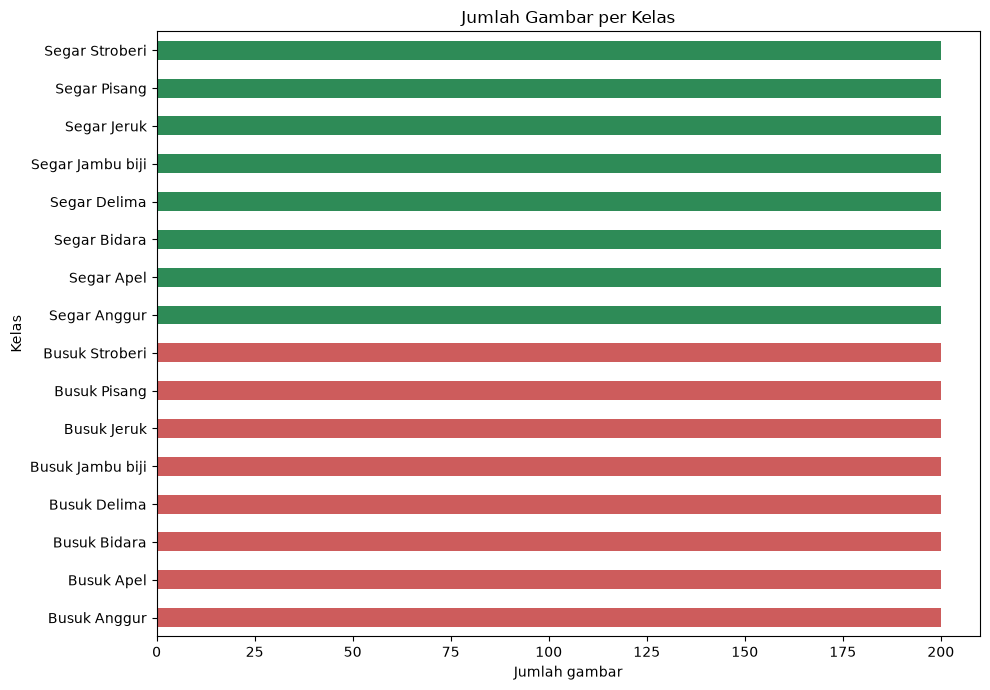

In [9]:
jumlah_per_kelas = (
    data_gambar["kelas"]
    .value_counts()
    .reindex(daftar_kelas, fill_value=0)
    .rename_axis("Kelas")
    .to_frame("Jumlah gambar")
)
display(jumlah_per_kelas)

warna_kelas = [
    "seagreen" if nama_kelas.startswith("Segar") else "indianred"
    for nama_kelas in jumlah_per_kelas.index
]
jumlah_per_kelas["Jumlah gambar"].plot(
    kind="barh", figsize=(10, 7), color=warna_kelas
)
plt.title("Jumlah Gambar per Kelas")
plt.xlabel("Jumlah gambar")
plt.ylabel("Kelas")
plt.tight_layout()
plt.show()

## 4. Pemeriksaan resolusi dan format gambar

Periksa metadata seluruh gambar, tampilkan jumlah per format, serta resolusi yang paling sering ditemukan.

In [10]:
metadata_gambar = []
gambar_tidak_valid = []

for baris in data_gambar.itertuples(index=False):
    try:
        with Image.open(baris.lokasi) as gambar:
            metadata_gambar.append(
                {
                    "format": gambar.format,
                    "lebar": gambar.width,
                    "tinggi": gambar.height,
                    "resolusi": f"{gambar.width} x {gambar.height}",
                }
            )
    except (UnidentifiedImageError, OSError) as error:
        gambar_tidak_valid.append({"lokasi": baris.lokasi, "error": str(error)})

if gambar_tidak_valid:
    print(f"Gambar tidak dapat dibaca: {len(gambar_tidak_valid)}")
    display(pd.DataFrame(gambar_tidak_valid))

ringkasan_metadata = pd.DataFrame(metadata_gambar)
if ringkasan_metadata.empty:
    raise ValueError("Tidak ada metadata gambar yang berhasil dibaca.")

print(f"Gambar berhasil diperiksa: {len(ringkasan_metadata):,}")
print(f"Jumlah resolusi unik: {ringkasan_metadata['resolusi'].nunique():,}")
print("Jumlah gambar per format:")
display(
    ringkasan_metadata["format"]
    .value_counts()
    .rename_axis("Format")
    .to_frame("Jumlah gambar")
)
print("10 resolusi yang paling sering ditemukan:")
display(
    ringkasan_metadata["resolusi"]
    .value_counts()
    .head(10)
    .rename_axis("Resolusi (lebar x tinggi)")
    .to_frame("Jumlah gambar")
)
print(
    "Rentang dimensi: "
    f"lebar {ringkasan_metadata['lebar'].min()}-"
    f"{ringkasan_metadata['lebar'].max()} px, "
    f"tinggi {ringkasan_metadata['tinggi'].min()}-"
    f"{ringkasan_metadata['tinggi'].max()} px"
)

Gambar berhasil diperiksa: 3,200
Jumlah resolusi unik: 2,274
Jumlah gambar per format:


,Jumlah gambar
Format,
JPEG,3200


10 resolusi yang paling sering ditemukan:


,Jumlah gambar
Resolusi (lebar x tinggi),
2560 x 1920,223
1920 x 2560,93
1200 x 1600,87
1600 x 1200,50
1040 x 780,18
577 x 433,17
780 x 1040,12
433 x 577,8
2560 x 2242,5


Rentang dimensi: lebar 251-2560 px, tinggi 301-2560 px


## 5. Contoh gambar setiap kelas

Tampilkan satu contoh gambar untuk setiap kombinasi jenis buah dan kondisi.

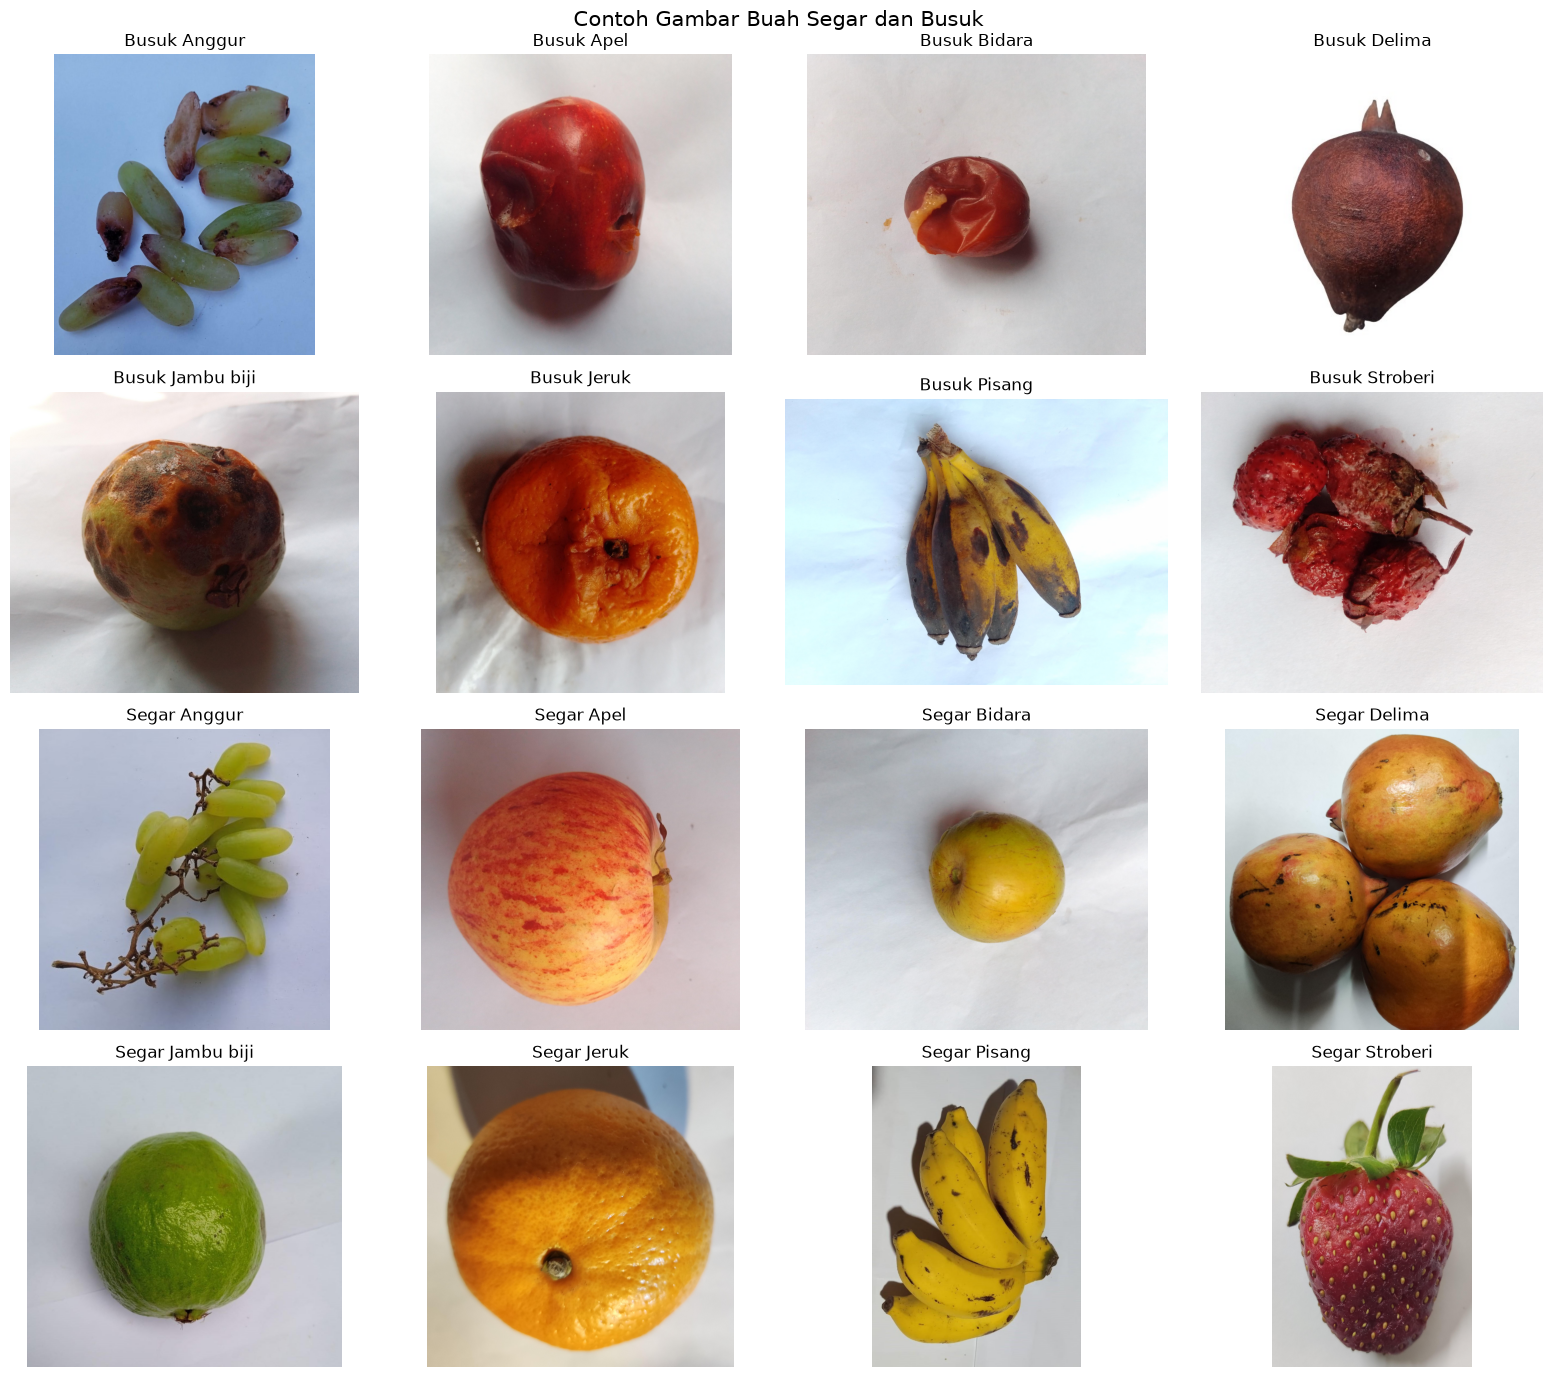

In [11]:
jumlah_contoh = min(
    CONTOH_PER_KELAS,
    int(data_gambar.groupby("kelas").size().min()),
)
contoh_gambar = (
    data_gambar.groupby("kelas", group_keys=False)
    .sample(n=jumlah_contoh, random_state=BENIH_ACAK)
    .reset_index(drop=True)
)

jumlah_kolom = min(4, len(daftar_kelas))
jumlah_baris = math.ceil(len(daftar_kelas) / jumlah_kolom)
fig, axes = plt.subplots(
    jumlah_baris,
    jumlah_kolom,
    figsize=(4 * jumlah_kolom, 3.5 * jumlah_baris),
    squeeze=False,
)

for nomor, nama_kelas in enumerate(daftar_kelas):
    sumbu = axes.flat[nomor]
    pilihan = contoh_gambar[contoh_gambar["kelas"] == nama_kelas].iloc[0]
    with Image.open(pilihan["lokasi"]) as gambar:
        sumbu.imshow(gambar.convert("RGB"))
    sumbu.set_title(nama_kelas)
    sumbu.axis("off")

for sumbu in axes.flat[len(daftar_kelas):]:
    sumbu.axis("off")

fig.suptitle("Contoh Gambar Buah Segar dan Busuk", fontsize=15)
fig.tight_layout()
plt.show()